# Projeto Andromeda-Net: Análise Exploratória (EDA) e Modelagem de Redes

Este notebook constrói e analisa o grafo de Fórmula 1 usando `NetworkX`, `Seaborn` e `nxviz`, baseando-se no barema do projeto e nas instruções de `formato-grafos`.

## Validação do ETL (Sanity Check)
Vamos garantir que a base processada não contém erros grotescos que resultem em nós isolados não intencionais.

In [1]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style='whitegrid')

DATA_PATH = '../../data/processed/f1_graph_base.csv'
df = pd.read_csv(DATA_PATH)
df.head()

,year,raceId,race_name,driverId,driver_name,nationality,constructorId,constructor_name,grid,position,points
0,2008,18,Australian Grand Prix,1,Lewis Hamilton,British,1,McLaren,1,1.0,10.0
1,2008,18,Australian Grand Prix,2,Nick Heidfeld,German,2,BMW Sauber,5,2.0,8.0
2,2008,18,Australian Grand Prix,3,Nico Rosberg,German,3,Williams,7,3.0,6.0
3,2008,18,Australian Grand Prix,4,Fernando Alonso,Spanish,4,Renault,11,4.0,5.0
4,2008,18,Australian Grand Prix,5,Heikki Kovalainen,Finnish,1,McLaren,3,5.0,4.0


## 1. EDA Clássica (Seaborn/Pandas)

Antes de ir para a teoria dos grafos, vamos entender os dados.
*(Aqui entrarão os plots de distribuição de pontos, construtores com mais vitórias, etc)*

/tmp/ipykernel_17591/4149567681.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_drivers.index, x=top_drivers.values, palette='viridis')


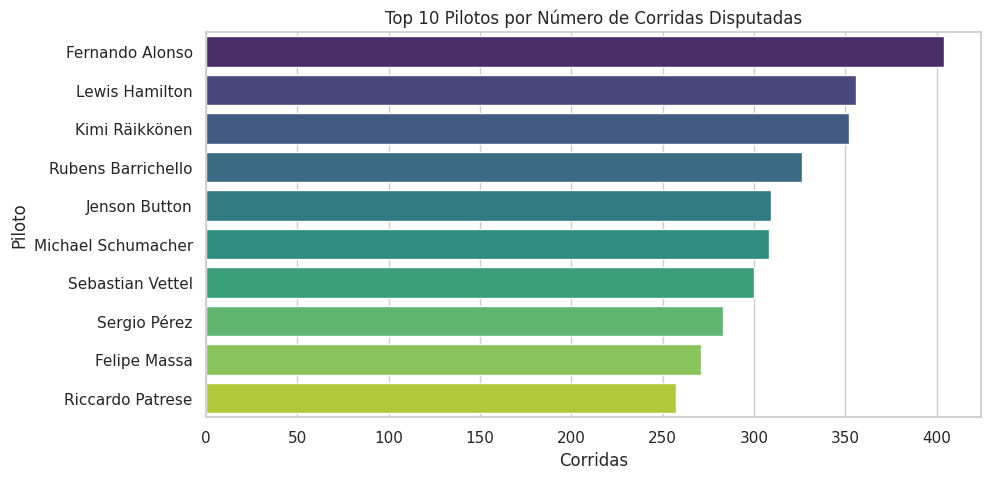

In [2]:
# Exemplo: Pilotos com mais participações na base de dados
plt.figure(figsize=(10, 5))
top_drivers = df['driver_name'].value_counts().head(10)
sns.barplot(y=top_drivers.index, x=top_drivers.values, palette='viridis')
plt.title('Top 10 Pilotos por Número de Corridas Disputadas')
plt.xlabel('Corridas')
plt.ylabel('Piloto')
plt.show()

## 2. Modelagem do Grafo (Bipartido: Piloto - Construtor)

Definição rigorosa:
- **Nós**: Pilotos e Construtores.
- **Arestas**: Representam que um Piloto correu por um Construtor.
- **Peso**: Número de corridas juntos.

In [3]:
# Agrupando conexões Piloto-Construtor e contando pesos
edge_list = df.groupby(['driver_name', 'constructor_name']).size().reset_index(name='weight')

# Criando o Grafo
B = nx.Graph()
B.add_nodes_from(edge_list['driver_name'], bipartite=0)
B.add_nodes_from(edge_list['constructor_name'], bipartite=1)
B.add_weighted_edges_from([tuple(x) for x in edge_list.values])

print(f'Nós: {B.number_of_nodes()}')
print(f'Arestas: {B.number_of_edges()}')

# Verificando nós isolados
isolates = list(nx.isolates(B))
print(f'Nós isolados não intencionais: {len(isolates)}')

Nós: 1072
Arestas: 2150
Nós isolados não intencionais: 0


## 3. Extração de Insights (Centralidade, etc)

Aqui aplicaremos os conceitos da disciplina (Centralidade de Grau, Betweenness, etc).

In [4]:
# Grau (Degree Centrality)
degree_dict = dict(B.degree(weight='weight'))
sorted_degree = sorted(degree_dict.items(), key=lambda item: item[1], reverse=True)
print('Top 5 maiores relacionamentos (Piloto ou Construtor, por corridas):')
for k, v in sorted_degree[:5]:
    print(f'{k}: {v} corridas')

Top 5 maiores relacionamentos (Piloto ou Construtor, por corridas):
Ferrari: 2439 corridas
McLaren: 1923 corridas
Williams: 1676 corridas
Tyrrell: 881 corridas
Team Lotus: 871 corridas


## 4. Projeção Unipartida: A Rede de Pilotos

Para calcular métricas avançadas baseadas nos indivíduos, vamos realizar uma **Projeção Bipartida** focando apenas nos Pilotos. Nessa nova rede, dois pilotos estarão conectados se já pilotaram para o **mesmo Construtor** ao longo de suas carreiras. Isso modela a rede de 'colegas de escuderia' ao longo da história da Fórmula 1.

In [5]:
from networkx.algorithms import bipartite

# O conjunto B criado anteriormente possui 'bipartite=0' para Pilotos e '1' para Construtores.
pilotos_nodes = {n for n, d in B.nodes(data=True) if d['bipartite'] == 0}

# Cria o grafo projetado ligando os pilotos.
G_pilotos = bipartite.projected_graph(B, pilotos_nodes)

print(f'Rede Unipartida (Pilotos) - Nós: {G_pilotos.number_of_nodes()}')
print(f'Rede Unipartida (Pilotos) - Arestas: {G_pilotos.number_of_edges()}')

Rede Unipartida (Pilotos) - Nós: 861
Rede Unipartida (Pilotos) - Arestas: 32889


## 5. Análise de Centralidade Avançada

Com a rede `Piloto <-> Piloto` em mãos, podemos analisar os aspectos topológicos do automobilismo:
- **Betweenness Centrality (Intermediação):** Mede quem atua como 'ponte'. Pilotos com alto Betweenness são aqueles que transitaram por muitas equipes periféricas e centrais, conectando diferentes eras ou 'bolhas' da F1.
- **Eigenvector Centrality (Autovetor):** Avalia a influência. Pilotos com alto Eigenvector não apenas têm muitas conexões, mas estão conectados a outros pilotos altamente conectados (a 'elite' da F1).

In [6]:
# Cálculo das centralidades (Pode levar alguns segundos)
betweenness = nx.betweenness_centrality(G_pilotos)
eigenvector = nx.eigenvector_centrality(G_pilotos, max_iter=1000)
degree = nx.degree_centrality(G_pilotos)

# Criando um DataFrame consolidado para facilitar a análise com Pandas/Seaborn
df_centrality = pd.DataFrame({
    'Degree': pd.Series(degree),
    'Betweenness': pd.Series(betweenness),
    'Eigenvector': pd.Series(eigenvector)
}).reset_index().rename(columns={'index': 'Driver'})

df_centrality.head()

,Driver,Degree,Betweenness,Eigenvector
0,Bob Bondurant,0.195349,0.002462,0.077896
1,Valtteri Bottas,0.124419,0.001867,0.030506
2,Alex Caffi,0.062791,0.000446,0.010789
3,Desmond Titterington,0.032558,0.000000,0.006419
4,Giancarlo Fisichella,0.220930,0.011501,0.066719


### 5.1 Visualização das Métricas: Quem são as pontes e a elite?

/tmp/ipykernel_17591/3473603523.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_bet, x='Betweenness', y='Driver', ax=axes[0], palette='magma')
/tmp/ipykernel_17591/3473603523.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_eig, x='Eigenvector', y='Driver', ax=axes[1], palette='viridis')


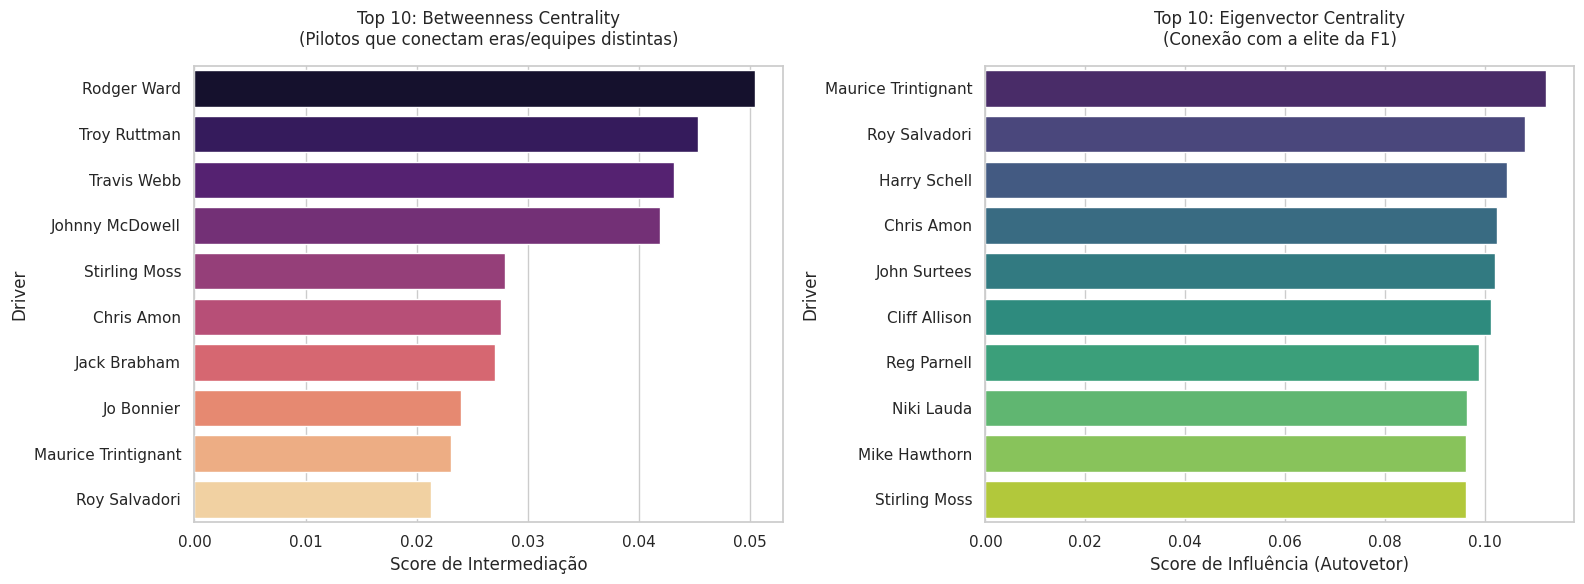

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Betweenness
top_bet = df_centrality.sort_values('Betweenness', ascending=False).head(10)
sns.barplot(data=top_bet, x='Betweenness', y='Driver', ax=axes[0], palette='magma')
axes[0].set_title('Top 10: Betweenness Centrality\n(Pilotos que conectam eras/equipes distintas)', pad=15)
axes[0].set_xlabel('Score de Intermediação')

# Gráfico 2: Eigenvector
top_eig = df_centrality.sort_values('Eigenvector', ascending=False).head(10)
sns.barplot(data=top_eig, x='Eigenvector', y='Driver', ax=axes[1], palette='viridis')
axes[1].set_title('Top 10: Eigenvector Centrality\n(Conexão com a elite da F1)', pad=15)
axes[1].set_xlabel('Score de Influência (Autovetor)')

plt.tight_layout()
plt.show()

## 6. Visualização Topológica (O Grafo da Elite)

Visualizar todos os nós simultaneamente geraria um 'Hairball' (bola de pelos) ilegível, o que é uma má prática. Para apresentar um grafo limpo, vamos extrair um **subgrafo** contendo os 50 pilotos de maior centralidade de Autovetor.

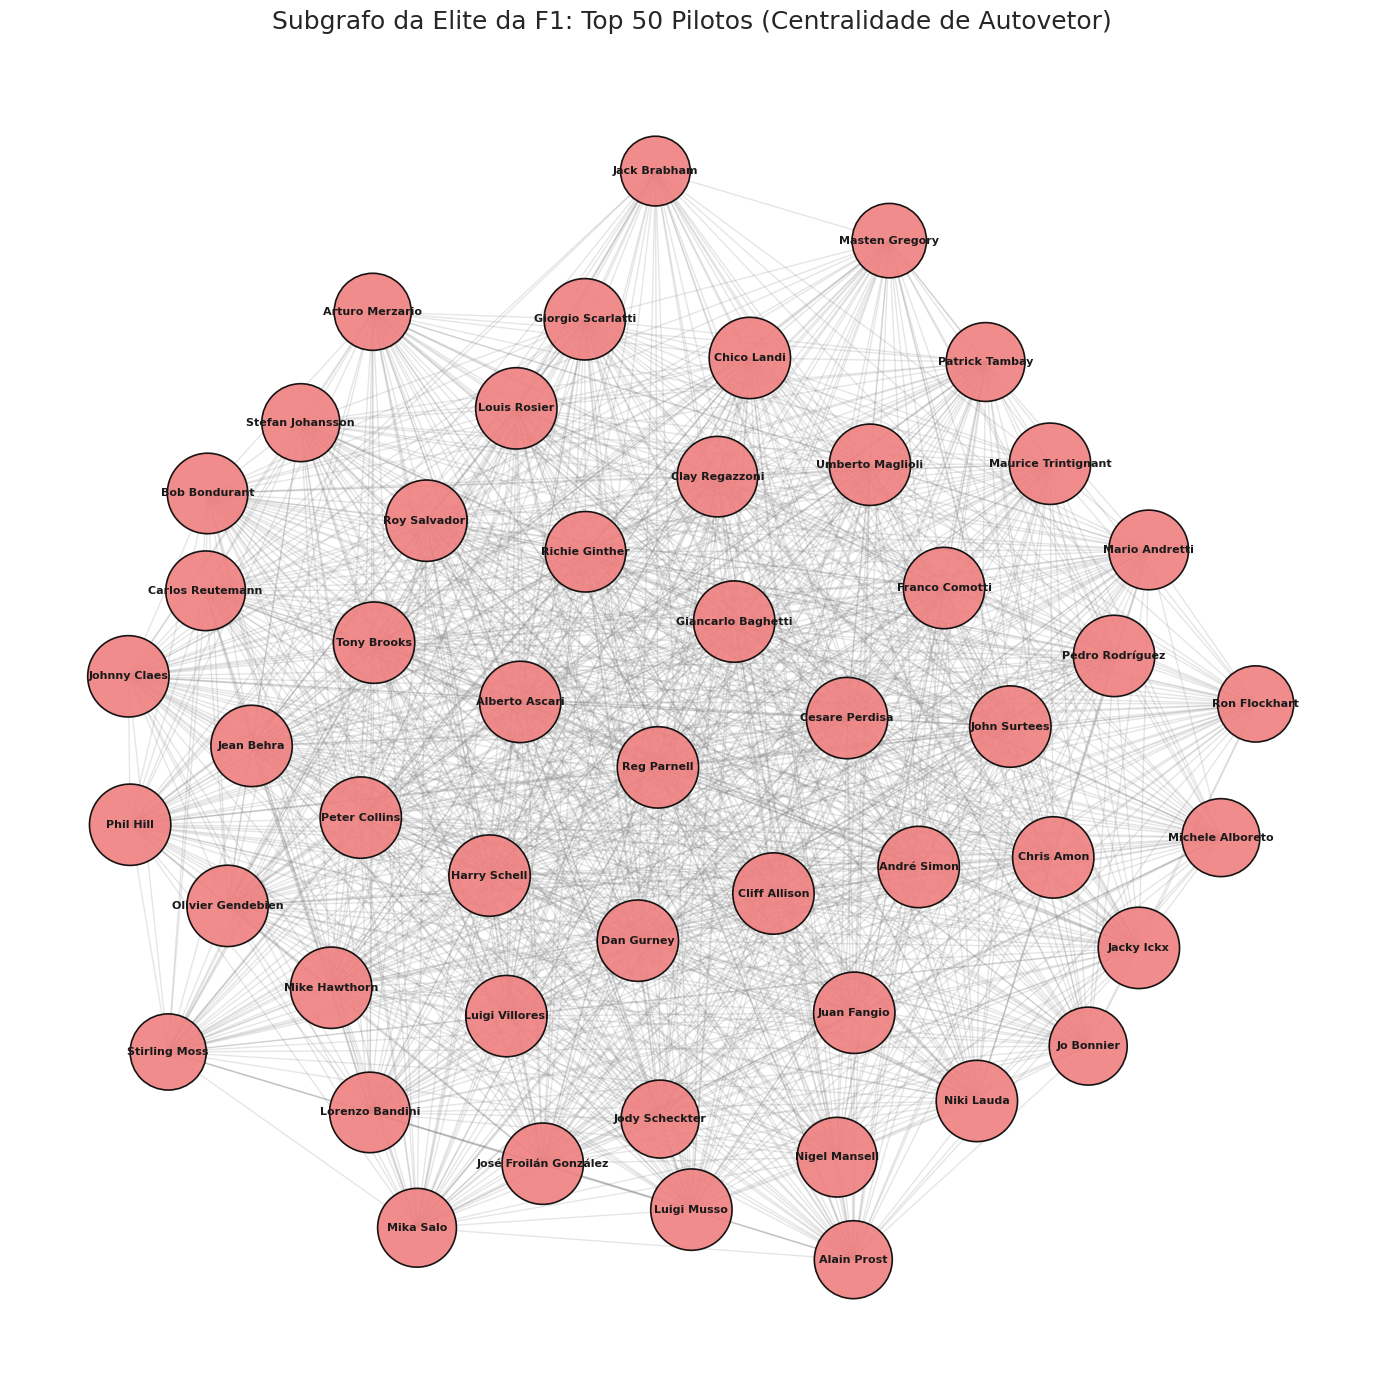

In [8]:
# Extrair a lista dos 50 maiores influenciadores da rede
top_50_drivers = df_centrality.sort_values('Eigenvector', ascending=False).head(50)['Driver'].tolist()
H = G_pilotos.subgraph(top_50_drivers)

plt.figure(figsize=(14, 14))
# Usando um layout baseando em molas (Fruchterman-Reingold) para espaçar os clusters
pos = nx.spring_layout(H, k=0.4, seed=42)

# O tamanho do nó será proporcional ao seu grau dentro do subgrafo
node_sizes = [dict(H.degree())[node] * 70 for node in H.nodes()]

nx.draw_networkx_nodes(H, pos, node_size=node_sizes, node_color='lightcoral', alpha=0.9, edgecolors='black', linewidths=1.2)
nx.draw_networkx_edges(H, pos, alpha=0.2, edge_color='gray')
nx.draw_networkx_labels(H, pos, font_size=8, font_family='sans-serif', font_weight='bold')

plt.title('Subgrafo da Elite da F1: Top 50 Pilotos (Centralidade de Autovetor)', fontsize=18, pad=20)
plt.axis('off')
plt.tight_layout()
plt.show()